In [1]:
import pandas as pd
import os

print("Current folder:", os.getcwd())
print("Files available:", os.listdir())

Current folder: C:\Users\ALL AtoZ\Cognifyz_Data_Analytics\Level_1
Files available: ['.ipynb_checkpoints', 'Cognifyz_Top_Cuisines', 'Untitled.ipynb']


In [2]:
import os
print(os.listdir())

['.ipynb_checkpoints', 'City_Analysis_Results.csv', 'Cognifyz_Top_Cuisines.ipynb', 'Online_Delivery_Percentage.png', 'Online_Delivery_Rating_Comparison.png', 'Online_Delivery_Results.csv', 'Price_Range_Distribution.csv', 'Price_Range_Distribution.png', 'Price_Range_Donut.png', 'Price_Range_Pie.png', 'Top_10_Cities.png', 'Top_10_Cuisines.csv', 'Top_10_Cuisines.png', 'Top_3_Cuisines.png', 'Top_3_Cuisines_Premium.png', 'Untitled.ipynb', 'zomato.csv']


In [3]:
import pandas as pd

df = pd.read_csv("zomato.csv", encoding="latin1")
print(df.shape)

(9551, 21)


In [4]:
df["Has Online delivery"].value_counts()

Has Online delivery
No     7100
Yes    2451
Name: count, dtype: int64

In [5]:
df["Has Online delivery"].value_counts(normalize=True).mul(100).round(2)

Has Online delivery
No     74.34
Yes    25.66
Name: proportion, dtype: float64

In [6]:
df.groupby("Has Online delivery")["Aggregate rating"].mean().round(2)

Has Online delivery
No     2.47
Yes    3.25
Name: Aggregate rating, dtype: float64

In [7]:
counts = df["Has Online delivery"].value_counts()
percentages = df["Has Online delivery"].value_counts(normalize=True) * 100
ratings = df.groupby("Has Online delivery")["Aggregate rating"].mean()

results = pd.DataFrame({
    "Restaurant Count": counts,
    "Percentage (%)": percentages.round(2),
    "Average Rating": ratings.round(2)
})

results.to_csv("Online_Delivery_Results.csv")
print(results)

                     Restaurant Count  Percentage (%)  Average Rating
Has Online delivery                                                  
No                               7100           74.34            2.47
Yes                              2451           25.66            3.25


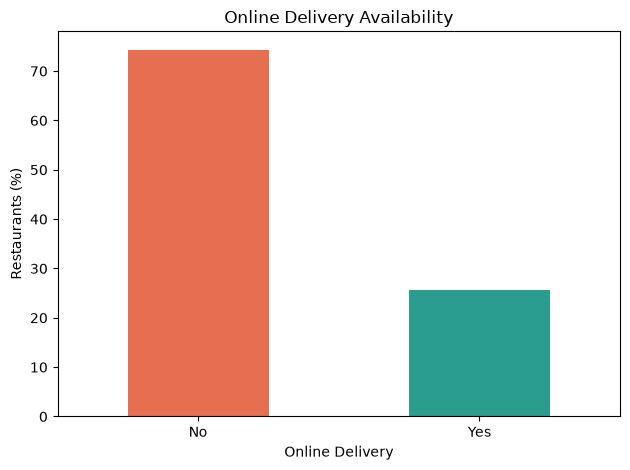

In [9]:
import matplotlib.pyplot as plt

percentages.round(2).plot(
    kind="bar",
    color=["#E76F51", "#2A9D8F"],
    title="Online Delivery Availability"
)

plt.ylabel("Restaurants (%)")
plt.xlabel("Online Delivery")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("Online_Delivery_Percentage.png", dpi=300, bbox_inches="tight")
plt.show()

### Insights: Online Delivery
- Only 25.66% of restaurants (2,451) offer online delivery, while 74.34% (7,100) do not.
- Restaurants with online delivery have a higher average rating (3.25) than those without (2.47).
- Online delivery availability is linked to better ratings, but this shows correlation, not proof of cause.

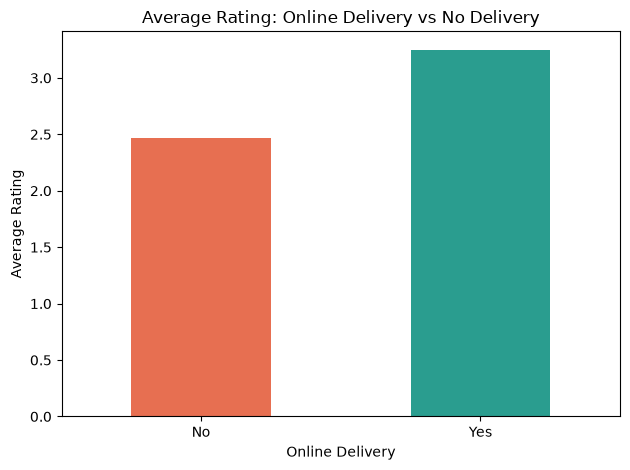

In [10]:
ratings = df.groupby("Has Online delivery")["Aggregate rating"].mean().round(2)

ratings.plot(
    kind="bar",
    color=["#E76F51", "#2A9D8F"],
    title="Average Rating: Online Delivery vs No Delivery"
)

plt.ylabel("Average Rating")
plt.xlabel("Online Delivery")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("Online_Delivery_Rating_Comparison.png", dpi=300, bbox_inches="tight")
plt.show()

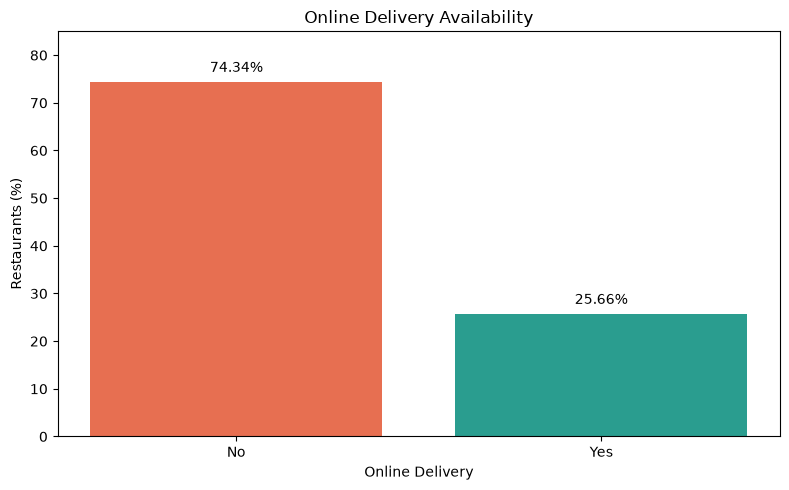

In [11]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    percentages.index,
    percentages.values,
    color=["#E76F51", "#2A9D8F"]
)

plt.title("Online Delivery Availability")
plt.xlabel("Online Delivery")
plt.ylabel("Restaurants (%)")
plt.bar_label(bars, fmt="%.2f%%", padding=5)
plt.ylim(0, 85)
plt.tight_layout()
plt.savefig("Online_Delivery_Percentage.png", dpi=300, bbox_inches="tight")
plt.show()